In [1]:
import scanpy as sc
import infercnvpy as cnv
import matplotlib.pyplot as plt
import numpy as np
from scipy.sparse import csr_matrix
import seaborn as sns

/usr/local/lib/python3.12/dist-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
adata = sc.read_h5ad('./data/scncc_with_nocancer_anno.h5ad')

In [3]:
adata.obs['anno_I'] = adata.obs['anno_I'].cat.rename_categories(
    {
        'Epi_Neural_pro': 'Epi_1',
        'Epi_Neuroendocrine': 'Epi_2',
        'Epi_Neuron_like': 'Epi_3'
    }
)

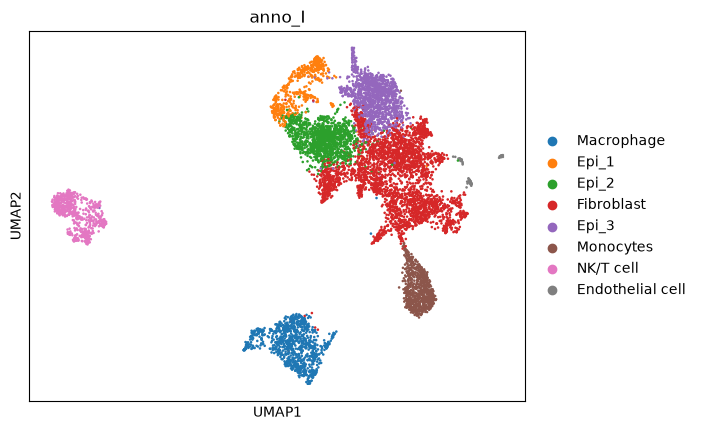

In [4]:
sc.pl.umap(adata, color='anno_I')

In [5]:
adata

AnnData object with n_obs × n_vars = 8729 × 18939
    obs: 'barcodes', 'batch', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_rb', 'pct_counts_rb', 'total_counts_hb', 'pct_counts_hb', 'total_counts_hsp', 'pct_counts_hsp', 'n_genes', 'group', 'predicted_celltype', 'predicted_probability', 'leiden', 'anno_I'
    var: 'mt', 'rb', 'hb', 'hsp', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'n_cells', 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm', 'highly_variable_nbatches'
    uns: 'anno_I_colors', 'batch_colors', 'group_colors', 'hvg', 'leiden', 'leiden_colors', 'log1p', 'neighbors', 'over_clustering', 'pca', 'predicted_celltype_colors', 'rank_genes_groups', 'umap'
    obsm: 'X_pca', 'X_pca_harmony', 'X_umap'
    varm: 'PCs'
    obsp: 'connectivities', 'distances'
    layers: 'counts', None (.X)

In [6]:
sc.pp.filter_genes(adata, min_cells=10)

In [7]:
adata.X = adata.layers['counts'].copy()

In [8]:
adata.X.data.max()

np.float64(12982.0)

In [9]:
adata

AnnData object with n_obs × n_vars = 8729 × 18677
    obs: 'barcodes', 'batch', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_rb', 'pct_counts_rb', 'total_counts_hb', 'pct_counts_hb', 'total_counts_hsp', 'pct_counts_hsp', 'n_genes', 'group', 'predicted_celltype', 'predicted_probability', 'leiden', 'anno_I'
    var: 'mt', 'rb', 'hb', 'hsp', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'n_cells', 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm', 'highly_variable_nbatches'
    uns: 'anno_I_colors', 'batch_colors', 'group_colors', 'hvg', 'leiden', 'leiden_colors', 'log1p', 'neighbors', 'over_clustering', 'pca', 'predicted_celltype_colors', 'rank_genes_groups', 'umap'
    obsm: 'X_pca', 'X_pca_harmony', 'X_umap'
    varm: 'PCs'
    obsp: 'connectivities', 'distances'
    layers: 'counts', None (.X)

In [16]:
import gtfparse

gtf = gtfparse.read_gtf('./gencode.v32.primary_assembly.annotation.gtf')

genepos = (gtf.loc[gtf["feature"] == "gene",
                   ["gene_name", "seqname", "start", "end"]]
              .rename(columns={"seqname": "chromosome"})
              .set_index("gene_name")
              .dropna())

# 关键改动 1：去掉重复的 gene_name，防止 join 膨胀
genepos = genepos[~genepos.index.duplicated(keep="first")]

# 关键改动 2：left join 保持形状不变
adata.var = adata.var.join(genepos, how="left")

# 关键改动 3：GTF 中没有坐标的基因，通过切片 adata 删除（同步裁剪 X）
missing = adata.var["chromosome"].isna().values
print(f"{missing.sum()} / {adata.n_vars} 个基因在 GTF 中没有坐标")
adata = adata[:, ~missing].copy()

# 检查一下，应该 18677 行、无缺失
adata.var[["chromosome", "start", "end"]].notna().all()

38 / 18677 个基因在 GTF 中没有坐标


chromosome    True
start         True
end           True
dtype: bool

In [17]:
adata.var[["chromosome", "start", "end"]].head()

,chromosome,start,end
features,,,
FAM87B,chr1,817371.0,819837.0
LINC00115,chr1,826206.0,827522.0
FAM41C,chr1,868071.0,876903.0
SAMD11,chr1,923928.0,944581.0
NOC2L,chr1,944203.0,959309.0


In [12]:
cnv.io.genomic_position_from_gtf(gtf_file= './gencode.v32.primary_assembly.annotation.gtf',
                                 adata = adata,
                                 gtf_gene_id='gene_name'
                                )

AttributeError: 'DataFrame' object has no attribute 'to_pandas'

In [18]:
# We provide all immune cell types as "normal cells".
cnv.tl.infercnv(
    adata,
    reference_key="anno_I",
    reference_cat=['NK/T cell', 'Monocytes', 'Macrophage'],
    lfc_clip=3,
    window_size=100,
    exclude_chromosomes=('chrX', 'chrY'),
    inplace=True
)

100%|██████████| 2/2 [00:14<00:00,  7.08s/it]


<Figure size 1600x1000 with 0 Axes>

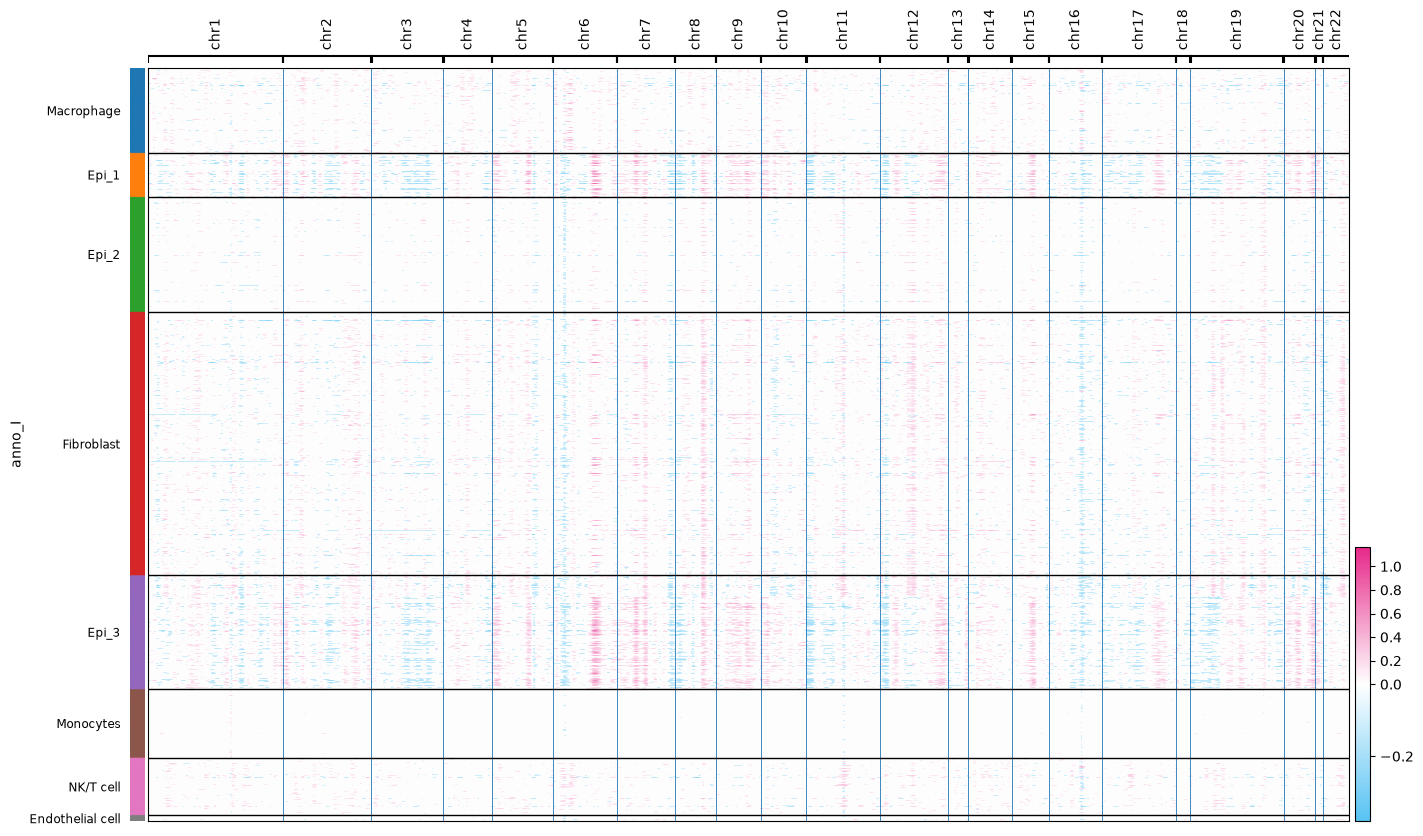

In [19]:
from matplotlib import colors

custom_colors = ["#57C3F3", "white", "#E7298A"]
cmap_custom = colors.LinearSegmentedColormap.from_list("my_gradient", custom_colors, N=128)

plt.figure(figsize=(16, 10))
ax = cnv.pl.chromosome_heatmap(adata, groupby="anno_I", show=False, cmap=cmap_custom)
plt.savefig('./fig/fig2_cnv_score_heatmap_modify.pdf', format='pdf', bbox_inches='tight')

In [20]:
adata = adata[adata.obs['anno_I'].str.startswith('Epi')].copy()

In [21]:
adata

AnnData object with n_obs × n_vars = 3160 × 18639
    obs: 'barcodes', 'batch', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_rb', 'pct_counts_rb', 'total_counts_hb', 'pct_counts_hb', 'total_counts_hsp', 'pct_counts_hsp', 'n_genes', 'group', 'predicted_celltype', 'predicted_probability', 'leiden', 'anno_I'
    var: 'mt', 'rb', 'hb', 'hsp', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'n_cells', 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm', 'highly_variable_nbatches', 'chromosome', 'start', 'end'
    uns: 'anno_I_colors', 'batch_colors', 'group_colors', 'hvg', 'leiden', 'leiden_colors', 'log1p', 'neighbors', 'over_clustering', 'pca', 'predicted_celltype_colors', 'rank_genes_groups', 'umap', 'cnv'
    obsm: 'X_pca', 'X_pca_harmony', 'X_umap', 'X_cnv'
    varm: 'PCs'
    obsp: 'connectivities', 'distances'
    layers: 'counts', None (.X)

In [22]:
cnv.tl.pca(adata)
cnv.pp.neighbors(adata, n_neighbors=20)
cnv.tl.leiden(adata, flavor='igraph', n_iterations=-1, resolution=0.2)

In [23]:
cnv.tl.cnv_score(adata)
cnv.tl.umap(adata)

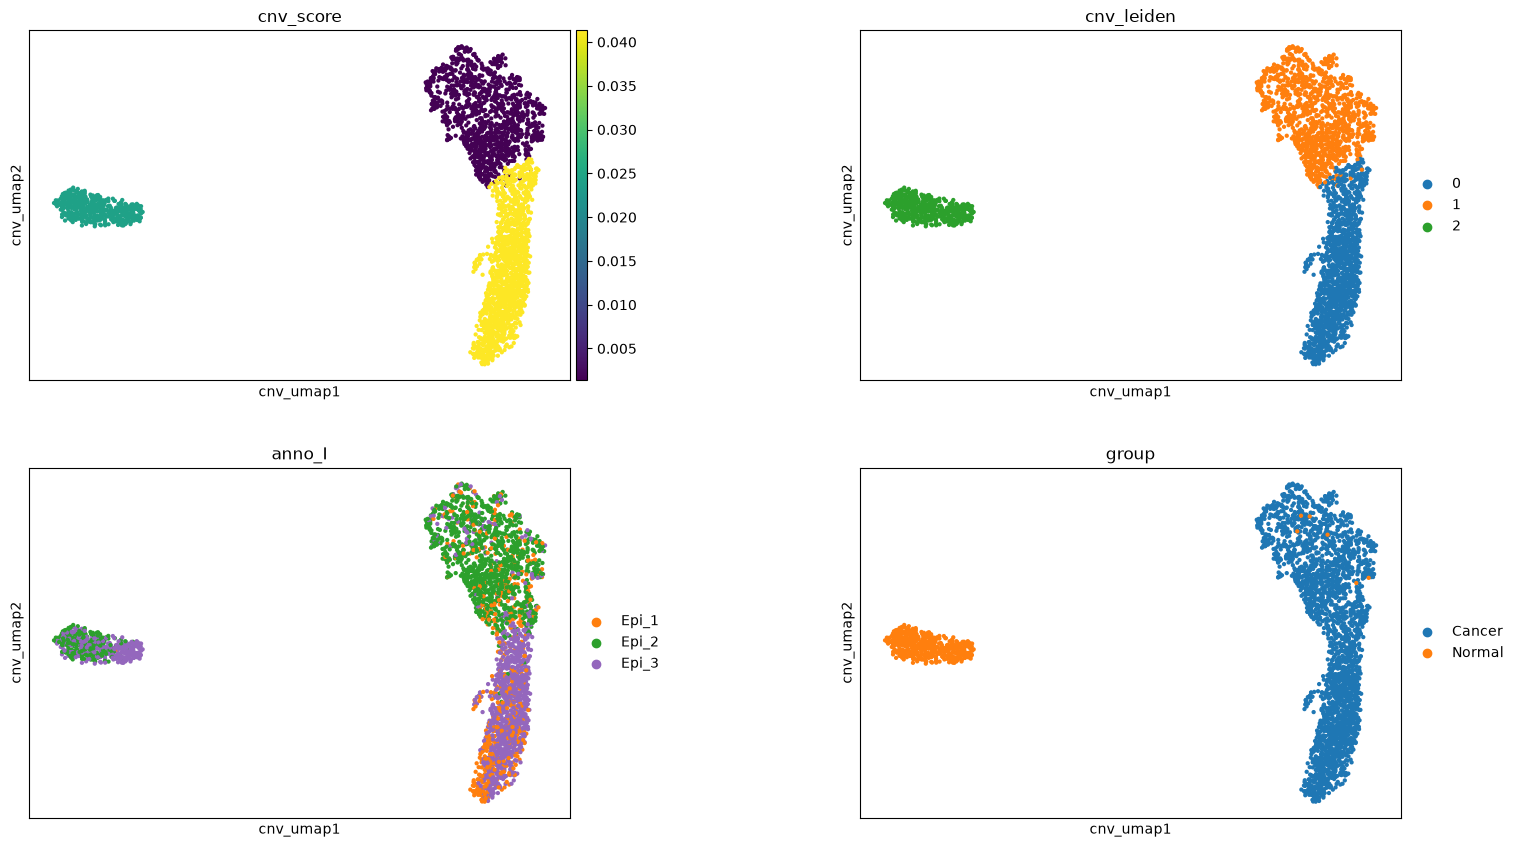

In [24]:
cnv.pl.umap(adata, color=["cnv_score", 'cnv_leiden', 'anno_I', 'group'], ncols=2, wspace=0.4)

In [25]:
import matplotlib.font_manager as fm
font_dir = './font/'
for ttf in fm.findSystemFonts(font_dir):
    fm.fontManager.addfont(ttf)

import matplotlib
plt.rcParams['font.family'] = 'Times New Roman'
matplotlib.rcParams['pdf.fonttype'] = 42
matplotlib.rcParams['ps.fonttype'] = 42

import logging
logging.getLogger("fontTools.subset").setLevel(logging.WARNING)

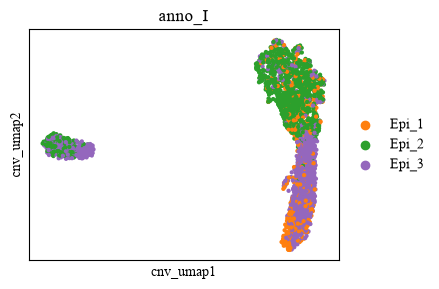

In [32]:
cnv_color_map = {
    '0': '#DC050C',
    '1': '#FB8072',
    '2': '#1965B0',
    '3': '#7BAFDE',
    '4': '#882E72',
    '5': '#B17BA6',
    '6': '#FF7F00',
    '7': '#00CC66',
    '8': '#99FFFF',
}

cnv.pl.umap(adata, color=['anno_I'],show=False)
plt.gcf().set_size_inches(4, 3) 
plt.savefig('./fig/fig2_cnv_anno_UMAP.pdf', format='pdf', bbox_inches='tight', transparent=True)

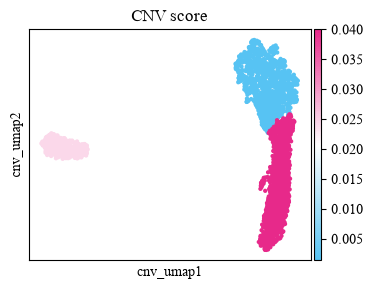

In [34]:
cnv.pl.umap(adata, color=['cnv_score'], vmax='0.04', cmap=cmap_custom, title="CNV score", show=False)
plt.gcf().set_size_inches(4, 3) 
plt.savefig('./fig/fig2_cnv_score_UMAP.pdf', format='pdf')

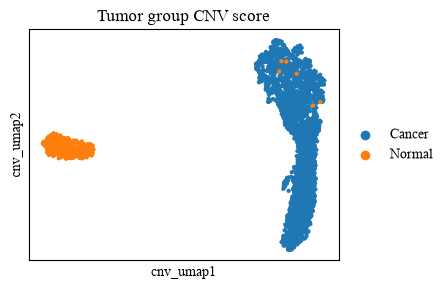

In [43]:
cnv.pl.umap(adata, color=['group'], vmax='0.04', title="Tumor group CNV score", show=False)
plt.gcf().set_size_inches(4, 3)
plt.savefig('./fig/figs2_cancer_normal_cnv_leiden_UMAP.pdf', format='pdf')

anno_I
Epi_2    1104
Epi_3    1038
Epi_1     509
Name: count, dtype: int64


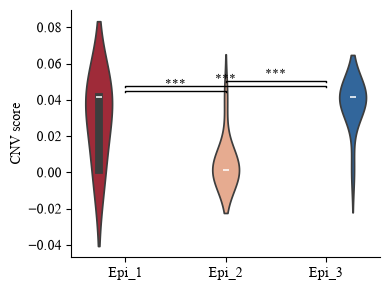

In [78]:
import itertools
import seaborn as sns
from scipy import stats
import matplotlib.pyplot as plt

df = adata.obs.loc[adata.obs['group'] == 'Cancer', ['anno_I', 'cnv_score']].copy()
df = df[df['anno_I'].str.contains('Epi', na=False)]
print(df['anno_I'].value_counts())

order = ['Epi_1', 'Epi_2', 'Epi_3']

celltype2color = {
    'Epi_1': '#B2182B',
    'Epi_2': '#F4A582',
    'Epi_3': '#2166AC',
}

fig, ax = plt.subplots(figsize=(4, 3))
sns.violinplot(data=df, x='anno_I', y='cnv_score', bw_adjust=4, inner='box',
               palette=celltype2color, hue='anno_I', legend=False, order=order,
               ax=ax)
ax.set_xlabel('')
ax.set_ylabel('CNV score')
ax.spines[['top', 'right']].set_visible(False)

# 两两比较 + 显著性括号
groups = {k: g['cnv_score'].to_numpy() for k, g in df.groupby('anno_I')}

def p_to_star(p):
    return '***' if p < 1e-3 else '**' if p < 1e-2 else '*' if p < 0.05 else 'ns'

ymin, ymax = df['cnv_score'].min(), df['cnv_score'].max()
step = (ymax - ymin) * 0.07
xpos = {name: i for i, name in enumerate(order)}



results = []
level = 0
for a, b in itertools.combinations(order, 2):
    p = stats.mannwhitneyu(groups[a], groups[b], alternative='two-sided').pvalue
    results.append({'group1': a, 'group2': b, 'pvalue': p})
    y = ymax + step * (level + 1)
    ax.plot([xpos[a], xpos[a], xpos[b], xpos[b]],
            [y, y + step*0.3, y + step*0.3, y], lw=1, c='k')
    ax.text((xpos[a] + xpos[b]) / 2, y + step*0.35, p_to_star(p),
            ha='center', va='bottom', fontsize=9)
    level = (level + 1) % 3

plt.tight_layout()
plt.savefig('./fig/cnv_score_epi_violin.pdf', bbox_inches='tight')
plt.show()

In [71]:
df.groupby(['anno_I']).median()

,cnv_score
anno_I,
Epi_1,0.041331
Epi_2,0.001377
Epi_3,0.041331


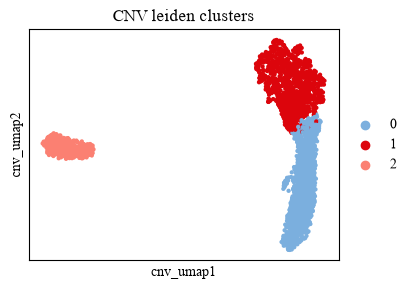

In [87]:
cmap_custom = {
    '0': '#7BAFDE',
    '1': '#DC050C',
    '2': '#FB8072',
    '3': '#1965B0',
}

cnv.pl.umap(adata, color=['cnv_leiden'],
            palette=cmap_custom,
            title='CNV leiden clusters',
            show=False)
plt.gcf().set_size_inches(4, 3)
plt.savefig('./fig/fig2_cnv_leiden_UMAP.pdf', format='pdf', bbox_inches='tight')

In [73]:
cnv_result = adata.obsm['X_cnv'].todense()
adata.obs['cnv_score_cells'] = np.abs(cnv_result).mean(axis=1)

In [74]:
plot_df = adata.obs[['cnv_leiden', 'cnv_score_cells']]
plot_df['cnv_leiden'] = plot_df['cnv_leiden'].astype(str)
#plot_df = plot_df[plot_df['anno_I'].isin(['Epi_Neural-progenitor', 'Epi_Neuroendocrine', 'Epi_Neuron-like'])]
plot_df.head()

,cnv_leiden,cnv_score_cells
CCGTCCGGTG_AACAGCATAG_L1,0,0.077368
CTCTAAGCAT_AACAGCATAG_L1,0,0.002405
TACAAGCACC_AACAGCATAG_L1,0,0.029152
ACCTCGTGAA_AACCTAGTAG_L1,0,0.100880
TTATGACCGG_AACCTAGTAG_L1,0,0.052092


<Figure size 400x400 with 0 Axes>

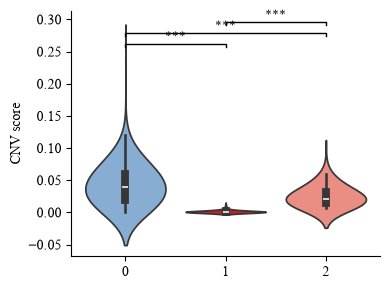

In [84]:
plt.figure(figsize=(4, 4))

celltype2color = {
    '1': '#DC050C',
    '2': '#FB8072',
    '3': '#1965B0',
    '0': '#7BAFDE',
    '4': '#882E72',
    '5': '#B17BA6',
    '6': '#FF7F00',
    'T cells': '#00CC66',
    'NK cell': '#99FFFF',
    'Endothelial cell': '#E7298A'
}

order = ['0', '1', '2']
fig, ax = plt.subplots(figsize=(4, 3))
sns.violinplot(data=plot_df, x='cnv_leiden', y='cnv_score_cells', bw_adjust=4, inner='box',
               palette=celltype2color, hue='cnv_leiden', legend=False, order=order,
               ax=ax)
ax.set_xlabel('')
ax.set_ylabel('CNV score')
ax.spines[['top', 'right']].set_visible(False)

# 两两比较 + 显著性括号
groups = {k: g['cnv_score_cells'].to_numpy() for k, g in plot_df.groupby('cnv_leiden')}

def p_to_star(p):
    return '***' if p < 1e-3 else '**' if p < 1e-2 else '*' if p < 0.05 else 'ns'

ymin, ymax = plot_df['cnv_score_cells'].min(), plot_df['cnv_score_cells'].max()
step = (ymax - ymin) * 0.07
xpos = {name: i for i, name in enumerate(order)}



results = []
level = 0
for a, b in itertools.combinations(order, 2):
    p = stats.mannwhitneyu(groups[a], groups[b], alternative='two-sided').pvalue
    results.append({'group1': a, 'group2': b, 'pvalue': p})
    y = ymax + step * (level + 1)
    ax.plot([xpos[a], xpos[a], xpos[b], xpos[b]],
            [y, y + step*0.3, y + step*0.3, y], lw=1, c='k')
    ax.text((xpos[a] + xpos[b]) / 2, y + step*0.35, p_to_star(p),
            ha='center', va='bottom', fontsize=9)
    level = (level + 1) % 3

plt.tight_layout()
plt.savefig('./fig/cnv_score_leiden_violin.pdf', bbox_inches='tight')
plt.show()

In [85]:
plot_df.groupby(['cnv_leiden']).median()

,cnv_score_cells
cnv_leiden,
0,0.039166
1,0.000738
2,0.020271


# monocle data prepare

In [56]:
selected_data = adata[(adata.obs['anno_I'].str.startswith('Epi_')) & (adata.obs['cnv_leiden'].isin(['0', '2']))].copy()
selected_data

AnnData object with n_obs × n_vars = 1920 × 18677
    obs: 'barcodes', 'batch', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_rb', 'pct_counts_rb', 'total_counts_hb', 'pct_counts_hb', 'total_counts_hsp', 'pct_counts_hsp', 'n_genes', 'group', 'predicted_celltype', 'predicted_probability', 'leiden', 'anno_I', 'cnv_leiden', 'cnv_score', 'cnv_score_cells'
    var: 'mt', 'rb', 'hb', 'hsp', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'n_cells', 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm', 'highly_variable_nbatches', 'chromosome', 'start', 'end', 'gene_id', 'gene_name'
    uns: 'anno_I_colors', 'batch_colors', 'group_colors', 'hvg', 'leiden', 'leiden_colors', 'log1p', 'neighbors', 'over_clustering', 'pca', 'predicted_celltype_colors', 'rank_genes_groups', 'umap', 'cnv', 'cnv_neighbors', 'cnv_leiden'
    obsm: 'X_pca', 'X_pca_harmony', 'X_umap', 'X_cnv', 'X_cnv_pca', 'X_cnv_umap'
   

In [57]:
selected_data.obs[['group', 'anno_I', 'cnv_leiden', 'cnv_score_cells']].reset_index().to_csv('02_monocle_meta.tsv.gz', sep='\t', header=None, index=False, compression='gzip')

In [58]:
selected_data.obs['cnv_leiden'].unique()

['0', '2']
Categories (2, object): ['0', '2']

In [59]:
from scipy import sparse
from scipy.io import mmwrite

In [60]:
ascites = sc.read_h5ad('./data/scncc_with_nocancer_anno.h5ad')
adata_for_save = ascites[selected_data.obs.index].copy()

In [61]:
adata_for_save

AnnData object with n_obs × n_vars = 1920 × 18939
    obs: 'barcodes', 'batch', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_rb', 'pct_counts_rb', 'total_counts_hb', 'pct_counts_hb', 'total_counts_hsp', 'pct_counts_hsp', 'n_genes', 'group', 'predicted_celltype', 'predicted_probability', 'leiden', 'anno_I'
    var: 'mt', 'rb', 'hb', 'hsp', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'n_cells', 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm', 'highly_variable_nbatches'
    uns: 'anno_I_colors', 'batch_colors', 'group_colors', 'hvg', 'leiden', 'leiden_colors', 'log1p', 'neighbors', 'over_clustering', 'pca', 'predicted_celltype_colors', 'rank_genes_groups', 'umap'
    obsm: 'X_pca', 'X_pca_harmony', 'X_umap'
    varm: 'PCs'
    layers: 'counts'
    obsp: 'connectivities', 'distances'

In [ ]:
sc.pp.filter_genes(adata_for_save, min_cells=10)

In [ ]:
adata_for_save

In [ ]:
adata_for_save.X = adata_for_save.layers['counts'].copy()

In [ ]:
adata_for_save.X.data.max()

In [ ]:
mmwrite("./02_monocle_matrix.mtx", adata_for_save.X.T)

In [ ]:
adata_for_save.var_names.to_series().to_csv('02_monocle_feature.tsv.gz', sep='\t', header=None, index=False, compression='gzip')